# Kuramoto Model of Coupled Oscillators
The Kuramoto model is a mathematical model used to describe synchronization. It consists of a population of coupled phase oscillators.

## 1. Simulating the Kuramoto Model
We simulate a network of oscillators with distributed natural frequencies and a global coupling constant $K$.


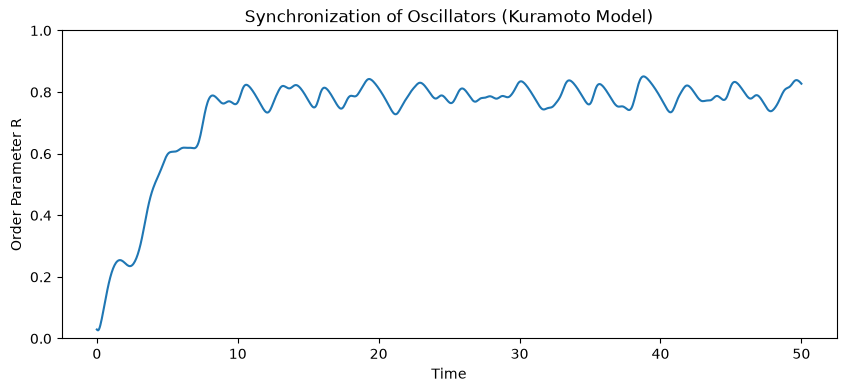

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Parameters
N = 50  # Number of oscillators
K = 2.0  # Coupling strength
omega = np.random.randn(N)  # Natural frequencies

def kuramoto(theta, t, omega, K, N):
    # theta is a vector of phases
    # Compute the mean field
    order_param = np.mean(np.exp(1j * theta))
    R = np.abs(order_param)
    Psi = np.angle(order_param)
    
    # Phase equations
    dtheta_dt = omega + K * R * np.sin(Psi - theta)
    return dtheta_dt

# Initial conditions (random phases)
theta0 = np.random.uniform(0, 2 * np.pi, N)

# Time array
t = np.linspace(0, 50, 1000)

# Integrate the equations
theta_t = odeint(kuramoto, theta0, t, args=(omega, K, N))

# Compute the order parameter over time
R_t = np.abs(np.mean(np.exp(1j * theta_t), axis=1))

plt.figure(figsize=(10, 4))
plt.plot(t, R_t)
plt.xlabel('Time')
plt.ylabel('Order Parameter R')
plt.title('Synchronization of Oscillators (Kuramoto Model)')
plt.ylim(0, 1)
plt.show()


## 2. Visualizing Oscillator Phases
We can plot the phases of the oscillators over time to see them synchronize.


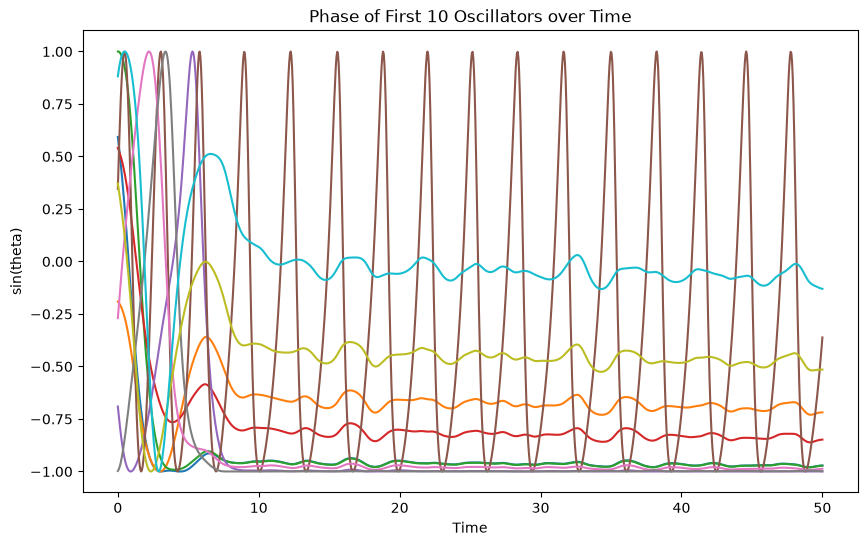

In [2]:
plt.figure(figsize=(10, 6))
plt.plot(t, np.sin(theta_t[:, :10])) # Plot first 10 oscillators
plt.xlabel('Time')
plt.ylabel('sin(theta)')
plt.title('Phase of First 10 Oscillators over Time')
plt.show()
